## **Project Description**

This project numerically solves Litvin's *equations of mesh* for a face gear-pinion pair, given the following:
* Cutting tool flank geometry, described as a 3D parametric surface with parameters $u$ and $v$
* Kinematically paired angular velocity vectors for the cutting tool and workpiece
* Tool path for the cutting tool, described as a function of time parameter $t$

---


## **Project Background**

Analytical representations of gear teeth are difficult to produce in non-planar gear systems. As the accessibility and quality of additive manufacturing solutions continues to increase, a rigourous method of defining complex gear geometry is increasingly relevant. 

One such solution for generating gear teeth is by simulating the motion of a member in a gear pair, and solving the *equation of mesh* for the resulting surface of the workpiece gear, as described by F. Litvin: $$\boldsymbol{\vec{n}}\cdot\boldsymbol{\vec{v}}=0$$
Where $\boldsymbol{\vec{n}}$ is the normal vector at a point on the cutting tool surface, and $\boldsymbol{\vec{v}}$ is the velocity vector of said point.

Such a process imitates traditional subtractive manufacturing methods, with the simulated member representing a cutting tool removing material from a stock workpiece gear blank. As such, this method can be trivially extended to any cutting tool geometry and tool path.

---


## **Source Code**


### **Library Initilization**

In [1]:
import numpy as np #type: ignore
from scipy.optimize import fsolve #type: ignore
import matplotlib.pyplot as plt #type: ignore

### **System Parameters**

In [2]:
module = 0.5
pressure_angle = np.deg2rad(20)
work_gear_teeth = 20
tool_gear_teeth = 12
spin_speed = 1.0                                                    # Angular speed of tool gear about its own axis
orbit_speed = -(spin_speed * (tool_gear_teeth/work_gear_teeth))     # Orbital speed of tool gear about work gear axis

In [3]:
def tooth_offset(m,n,r):
    num = ((m*n) + 2*m)**2
    den = 4 *(r**2)
    trim = np.sqrt((num/den) - 1)

    inv = np.tan(pressure_angle) - pressure_angle
    shift = inv + np.pi/(2*n) + np.pi/2

    return(trim, -shift)

In [4]:
tool_pitch_diameter = module*tool_gear_teeth
work_pitch_diameter = module*work_gear_teeth
tool_base_diameter = tool_pitch_diameter * np.cos(pressure_angle)
work_base_diameter = work_pitch_diameter * np.cos(pressure_angle)
tool_tip_diameter = tool_pitch_diameter + (2*module)
work_tip_diameter = work_pitch_diameter + (2*module)

tool_rp = tool_pitch_diameter / 2
work_rp = work_pitch_diameter / 2
tool_rb = tool_base_diameter / 2

g, s = tooth_offset(module,tool_gear_teeth, tool_rb)


### **Tool Surface Geometry and Surface Normals**

In [5]:
def origin_tool_surface(u,v):
    """
    Defines the 3D parametric cutting tool surface and corresponding tangents in its own local coordinate system. The tool surface in this example is a pinion cutter, defined by the involute curve where v is the flank parameter and u is the width parameter.

    Args:
        u (float): bounded parameter value rep

    Returns:
        surface (ndarray): 3D coordinate array of the involute tool surface
        normal_vector (ndarray): Array of normalized surface normals for all points defined in surface array
    """
    _, s = tooth_offset(module,tool_gear_teeth, tool_rb)
    x0 = u
    y0 = tool_rb*np.cos(v+s) + tool_rb*v*np.sin(v+s)
    z0 = tool_rb*np.sin(v+s) - tool_rb*v*np.cos(v+s)

    dx_du = 1
    dy_du = 0
    dz_du = 0

    dx_dv = 0
    dy_dv = tool_rb*v*np.cos(v+s)
    dz_dv = tool_rb*v*np.sin(v+s)

    t_u = np.array([dx_du, dy_du, dz_du])
    t_v = np.array([dx_dv, dy_dv, dz_dv])

    normal_vector = np.linalg.cross(t_u, t_v, axis=0)
    normal_vector /= np.linalg.norm(normal_vector)

    return np.array([x0, y0, z0]), normal_vector

In [6]:
def global_transform(u,v,t):
    """
    Defines a transformation function from local space to global space in terms of time parameter t

    Transformation: Local definition -> tool axis rotation -> work pitch radius translation -> work axis orbital rotation

    Returns:

    """

    theta = spin_speed * t
    R_spin = np.array([
        [1, 0, 0],
        [0, np.cos(theta), -np.sin(theta)],
        [0, np.sin(theta),  np.cos(theta)]
        ])

    T_pitch = np.array([work_rp, 0, 0])

    phi = orbit_speed * t
    R_orbit = np.array([
        [np.cos(phi), -np.sin(phi), 0],
        [np.sin(phi),  np.cos(phi), 0],
        [0, 0, 1]
    ])

    r_origin, n_origin = origin_tool_surface(u,v)                           # Cutting tool geometry defined from the system origin (coordinates if tool frame is stationary)
    r_local = R_spin @ r_origin                                             # Cutting tool geometry transformed to angular position dictated by time t (coordinates if pitch frame is stationary)
    r_translated = r_local.T + T_pitch
    r_global = R_orbit @ (r_local.T + T_pitch).T                            # Cutting tool geometry with transformed to orbital and angular position per time t (coordinates if work frame is stationary)
    n_global = R_orbit @ R_spin @ n_origin                                  # Analagous transformation from origin frame to global frame (work frame is stationary)

    spin_velocity = np.array([spin_speed, 0, 0])                            # Angular velocity vector representing tool spin about its own axis (x)
    orbital_velocity = np.array([0, 0, orbit_speed])                        # Angular velocity vector representing tool orbit about the work axis (z)

    v_spin_local = np.linalg.cross(spin_velocity, r_local, axis=0)          # Tangential velocity from tool spin calculated from pitch frame (if origin frame, then velocity is 0 since tool is "stationary")
    v_spin_global = R_orbit @ v_spin_local                                  # Tangential velocity from tool spin transformed to global frame (work frame is stationary)
    v_orbit_global = np.linalg.cross(orbital_velocity, r_global, axis=0)    # Tangential velocity from tool orbit calculated at global frame
    v_total = v_spin_global + v_orbit_global

    return (r_global, n_global, v_total)


### **Objective Function**

In [7]:
def equation_of_mesh(v_guess,u,t):
    r, n, v = global_transform(u,v_guess[0],t)
    return(np.dot(n,v))


### **Solver**

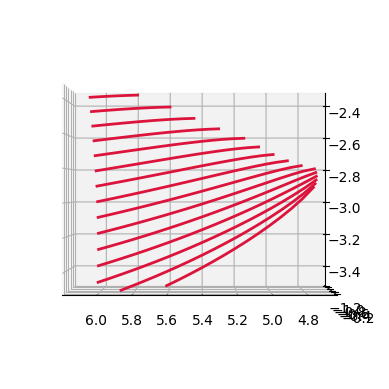

In [8]:


u0 = np.linspace(-0.25,1,20).tolist()#(0,3,50)
#v0 = np.array([0])#np.linspace(0,0.5,6)#(0,0.8,50)
t0 = np.linspace(0,1,20).tolist()

valid_parameters = []
v_guess = 0.3

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

for t in t0:
    v_guess = 0.3
    for u in u0:
        ier = 0
        while not ier:
            v_check = v_guess

            v_valid,_,ier,mesg = fsolve(equation_of_mesh,v_check,args=(u,t),full_output=True)

            if ier and v_valid[0] > 0 and v_valid[0] <= g:
                coord,_,_ = global_transform(u,v_valid[0],t)
                x_g, y_g, z_g = coord
                #print(f"solution found at u={u},v={v_valid[0]} at t={t},\nGlobal coordinate ({x_g},{y_g},{z_g})")
                valid_parameters.append((x_g, y_g, z_g))
            else:
                v_guess += 0.1
                #print(mesg)
    if valid_parameters:
        x, y, z = zip(*valid_parameters)
        ax.plot(x, y, z, color='crimson', linewidth=2)
        valid_parameters = []
    else:
        pass

ax.set_aspect('equal')
ax.view_init(elev=0, azim=90)
plt.show()


### **Plotter**